<a href="https://colab.research.google.com/github/k1-r1ll/pytorch/blob/main/11_pytorch_SGD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1:11:00

In [ ]:
#  House Price Estimation from Visual and Textual Features

In [42]:
import torch
from random import randint
import matplotlib.pyplot as plt
import torch.optim as optim

In [66]:
# Функция линейной модели, описывющей данные (скалярное произведение признаков на вектор весов)
def model(X, w):
  return X @ w

In [67]:
N = 2 # размерность вектора весов
w = torch.FloatTensor(N).uniform_(-1e-5, 1e-5) # генерируем случайный вектор весов заданной размерности из равномерного распределения
w.requires_grad_(True) # считаем по вектору градиенты
x = torch.arange(0, 3, 0.1)

In [68]:
y_train = 0.5 * x + 0.2 * torch.sin(2*x) - 3.0
x_train = torch.tensor([[_x ** _n for _n in range(N)] for _x in x]) # преобразование для удобства

In [69]:
x_train[:3]

tensor([[1.0000, 0.0000],
        [1.0000, 0.1000],
        [1.0000, 0.2000]])

In [70]:
total = len(x) # Размер обучающей выборки
lr = torch.tensor([0.1, 0.01]) # Шаг сходимости (первый шаг для w0, а второй для w1)

In [71]:
#loss_func = torch.nn.MSELoss()
loss_func = torch.nn.L1Loss()

#optimizer = optim.SGD(params=[w], lr=0.01, momentum=0.8, nesterov=True)
optimizer = optim.Adam(params=[w], lr=0.01)

In [72]:
for _ in range(1000):
  k = randint(0, total-1)
  y = model(x_train[k], w)
  #loss = (y - y_train[k])**2
  loss = loss_func(y, y_train[k])
  loss.backward()

  # w.data = w.data - lr * w.grad
  # w.grad.zero_()
  optimizer.step()
  optimizer.zero_grad()

tensor([-2.7691,  0.3350], requires_grad=True)


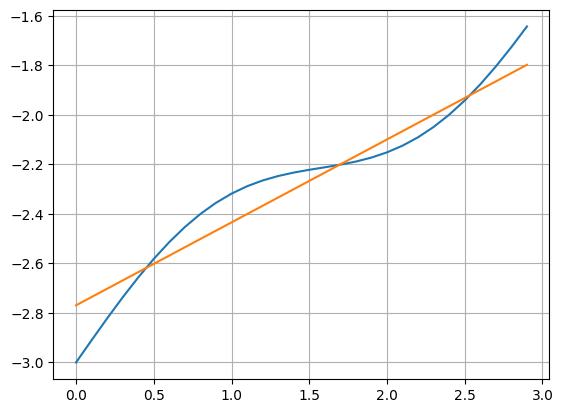

In [73]:
print(w)
predict = model(x_train, w)

plt.plot(x, y_train.numpy())
plt.plot(x, predict.data.numpy())
plt.grid()
plt.show()